# 01 · EDA — Domestic Flight Price (Regression)

**Goal of this notebook:** understand the data well enough to justify every preprocessing and modelling choice that follows. Each section asks one question, answers it with a plot or table, and ends with an **Observations** cell that feeds the report (Section 2 of the report follows the same numbering).

| § | Question |
|---|---|
| 2.1 | What does the target look like? |
| 2.2 | How much does cabin class matter? |
| 2.3 | Do airlines price differently? |
| 2.4 | How do stops and duration relate to price? |
| 2.5 | How does price change as departure approaches? |
| 2.6 | Do time slots and routes matter? |
| 2.7 | Data quality: missing values, recoverability, duplicates |
| 2.8 | Is the test set distributed like train? |

**What this cell does:** Turns on auto-reload, finds the project root (the folder containing `src/`), adds it to Python's import path, and imports our shared `config` module.

**Why:** Notebooks live in `notebooks/regression/`, so Python can't see `src/` by default. This cell makes `from src import config` work both locally and on Kaggle. Auto-reload means that if we later edit a file in `src/`, the notebook picks up the change without restarting the kernel.

In [1]:
%load_ext autoreload
%autoreload 2
import sys
from pathlib import Path

# Make `src` importable: repo root locally, or an uploaded Kaggle dataset containing src/
for p in [Path.cwd(), *Path.cwd().parents, *(f.parent.parent for f in Path("/kaggle/input").glob("**/src/config.py"))]:
    if (p / "src" / "config.py").exists():
        sys.path.insert(0, str(p.resolve()))
        break

from src import config

**What this cell does:** Imports the libraries, sets the plot style, defines a small `save()` helper, loads train/test/sample-submission through `config.load()`, and fixes the display order for categories (stops, time slots, class). Then it shows the first 5 rows.

**Why:** Loading through `config` means no hard-coded file paths, so the same notebook runs on Kaggle. The `save()` helper writes every figure to `results/regression/figures/` so the report can reuse it. Fixed category orders keep plots readable (stops as zero → one → two+, not alphabetical).

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

TASK = "regression"
FIG_DIR = config.results_dir(TASK) / "figures"
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 140)

def save(name):
    """Save the current figure for the report, then show it."""
    plt.savefig(FIG_DIR / f"eda_{name}.png", dpi=120, bbox_inches="tight")
    plt.show()

train, test, sample_sub = config.load(TASK)
TARGET = config.TARGETS[TASK]

# Fixed category orders so every plot reads the same way
STOPS = ["zero", "one", "two_or_more"]
SLOTS = ["Early_Morning", "Morning", "Afternoon", "Evening", "Night", "Late_Night"]
CLASSES = ["Economy", "Business"]

print("train", train.shape, "| test", test.shape, "| sample_submission", sample_sub.shape)
train.head()

train (15589, 12) | test (3898, 11) | sample_submission (3898, 2)


,id,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,flight_class,duration,days_left,price
0,1,Wayfarer Aviation,IX 1070,Metropolis,Evening,zero,Night,Springfield,Economy,NaN,18,8909
1,2,Oceanic Airlines,6E 285,Los Santos,Night,zero,Night,Springfield,Economy,1.33,38,5115
2,3,Wayfarer Aviation,AI 2641,Night City,Evening,zero,Night,Springfield,Business,2.08,13,35247
3,4,Oceanic Airlines,6E 6704,Night City,Afternoon,zero,Evening,Metropolis,Economy,2.25,5,6457
4,5,Oceanic Airlines,6E 234,Hill Valley,Evening,one,Night,Springfield,Economy,4.83,21,6842


**What this cell does:** Prints each column's data type and how many non-missing values it has.

**Why:** This is the first sanity check: which columns are numeric vs text (categorical), and which have gaps. Non-null counts below 15,589 show that `airline` and `duration` have missing values, which section 2.7 investigates.

In [3]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15589 entries, 0 to 15588
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id                15589 non-null  int64  
 1   airline           12500 non-null  object 
 2   flight            15589 non-null  object 
 3   source_city       15589 non-null  object 
 4   departure_time    15589 non-null  object 
 5   stops             15589 non-null  object 
 6   arrival_time      15589 non-null  object 
 7   destination_city  15589 non-null  object 
 8   flight_class      15589 non-null  object 
 9   duration          12494 non-null  float64
 10  days_left         15589 non-null  int64  
 11  price             15589 non-null  int64  
dtypes: float64(1), int64(3), object(8)
memory usage: 1.4+ MB


## 2.1 Target distribution

**Why look:** the shape of `price` decides the loss we can sensibly minimise. Least squares assumes roughly symmetric (Gaussian) errors — the MLE view from lecture. A long right tail means a few expensive tickets dominate the squared error.

**What this cell does:** Prints summary statistics of `price`, computes its skewness before and after taking the log, and plots both histograms side by side.

**Why:** Skewness measures how lopsided a distribution is (0 = symmetric). Least squares implicitly assumes roughly symmetric errors. If price is very lopsided, the few huge prices dominate the squared error. Comparing raw vs log shows whether a log transform fixes that.

count     15589.0
mean      29817.0
std       39128.0
min        3801.0
25%        7210.0
50%       10183.0
75%       35968.0
max      323177.0

skewness raw: 2.70 | skewness log: 0.71


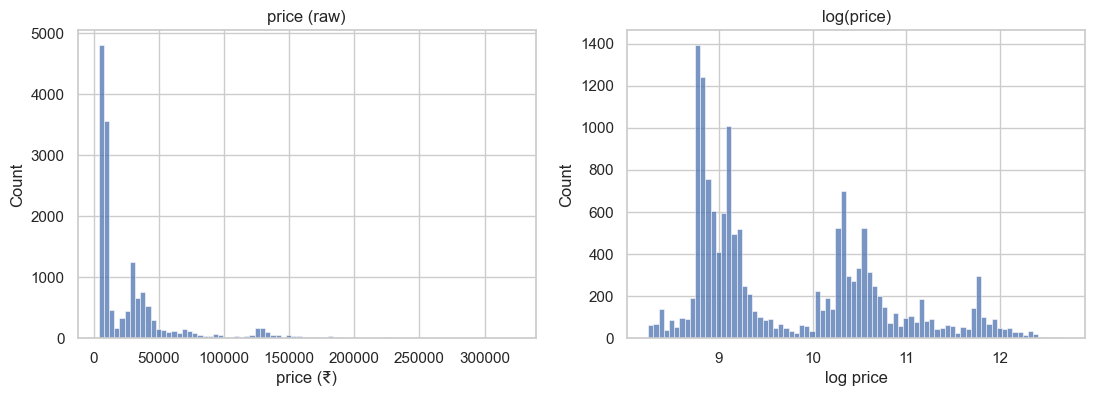

In [4]:
print(train[TARGET].describe().round(0).to_string())
print(f"\nskewness raw: {train[TARGET].skew():.2f} | skewness log: {np.log(train[TARGET]).skew():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(train[TARGET], bins=80, ax=axes[0])
axes[0].set(title="price (raw)", xlabel="price (₹)")
sns.histplot(np.log(train[TARGET]), bins=80, ax=axes[1])
axes[1].set(title="log(price)", xlabel="log price")
save("2_1_target")

**Observations (2.1)**

- Price runs from ₹3,801 to ₹323,177. Median ₹10,183 vs mean ₹29,817, skewness **2.70**.
- Taking the log cuts skewness to **0.71**, but log(price) is still **bimodal**, with two humps around 9 and 10.5. So the skew isn't just a long tail; it comes from two separate populations (see 2.2).
- **Implication:** least squares on raw price will be dominated by the expensive tickets. Training on log(price) is the natural fix (errors become roughly multiplicative, i.e. percentage errors). Whether we *should* depends on the Kaggle metric (still unconfirmed): RMSE on raw price rewards getting the expensive tickets right.

## 2.2 Cabin class

**Why look:** the two humps in log(price) above suggest two populations. If `flight_class` explains them, it's the single most important feature and a candidate for separate models per class (plan model #6).

**What this cell does:** Splits price statistics by `flight_class`, overlays the log-price histograms of Economy and Business, draws box plots per class, and prints the ratio of the two medians.

**Why:** The log-price histogram in 2.1 had two humps. If each hump is one class, then class explains most of the price and it becomes the key feature to model. We use medians rather than means because the means get pulled up by the long tail.

               count     mean      std      min      25%      50%      75%       max
flight_class                                                                        
Business      6380.0  60127.0  46415.0  15544.0  30767.0  38546.0  70441.0  323177.0
Economy       9209.0   8818.0   4670.0   3801.0   6740.0   7587.0   9340.0   74691.0


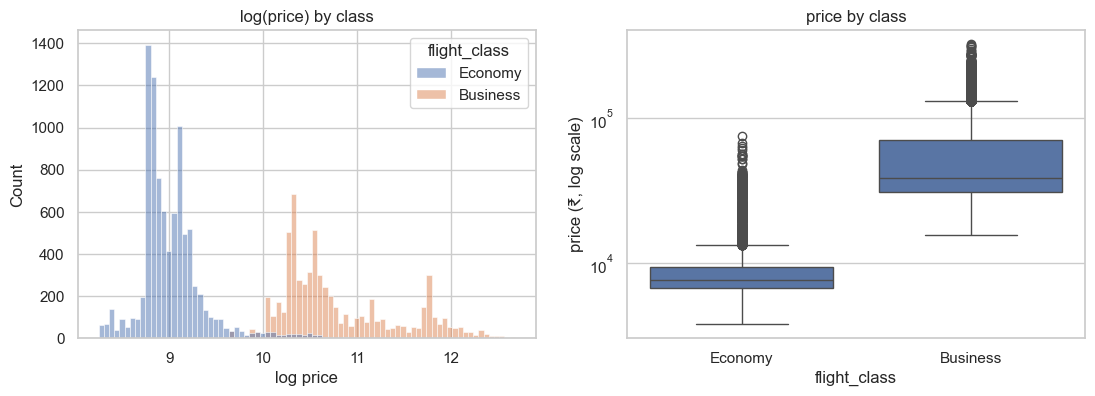


median Business / median Economy = 5.1x


In [5]:
print(train.groupby("flight_class")[TARGET].describe().round(0).to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(data=train, x=np.log(train[TARGET]), hue="flight_class", hue_order=CLASSES, bins=80, ax=axes[0])
axes[0].set(title="log(price) by class", xlabel="log price")
sns.boxplot(data=train, x="flight_class", y=TARGET, order=CLASSES, ax=axes[1])
axes[1].set(title="price by class", yscale="log", ylabel="price (₹, log scale)")
save("2_2_class")

ratio = train.groupby("flight_class")[TARGET].median()
print(f"\nmedian Business / median Economy = {ratio['Business'] / ratio['Economy']:.1f}x")

**Observations (2.2)**

- The class split explains the bimodality: Economy median ₹7,587, Business median ₹38,546, a **5.1×** gap. The two log-price distributions barely overlap.
- **`flight_class` alone explains R² = 0.78 of the variance in log(price)** (see 2.3). It's the single most important feature.
- Business prices also spread much more (std ₹46k vs ₹4.7k).
- **Implication:** any linear model needs class as a feature, and probably class × other-feature interactions, because the effect of airline, duration etc. differs by class. Separate models per class (plan model #6) are well justified.

## 2.3 Airline

**Why look:** airlines may have different fare levels, but we must compare *within* class — an airline that only sells Economy will look cheap just because of its class mix (a confounder).

**What this cell does:** Builds a table per airline: number of rows, share of its tickets that are Business, and median price.

**Why:** Before comparing airlines we need to know their **class mix**. An airline selling mostly Business will look "expensive" even if each of its fares is normal for its class. This table exposes that confounder, and also shows which airlines have so few rows that their estimates are unreliable.

In [6]:
air = (train.groupby("airline")
          .agg(n=(TARGET, "size"),
               business_share=("flight_class", lambda s: (s == "Business").mean()),
               median_price=(TARGET, "median"))
          .sort_values("n", ascending=False))
air["business_share"] = air["business_share"].round(2)
air

,n,business_share,median_price
airline,,,
Wayfarer Aviation,5200,0.48,14200.5
Oceanic Airlines,5112,0.26,8759.0
Sandpiper Air,697,0.03,7851.0
Stark Aviation,336,0.91,130960.0
Ajira Airways,330,0.84,71716.0
Nakatomi Airlines,319,0.88,133515.0
Wayne Enterprises Air,180,0.93,101561.5
Vandelay Aviation,115,0.00,7719.0
Virtucon,85,0.99,133809.0


**What this cell does:** Keeps airlines with at least 50 rows, then draws price box plots per airline, split by class (log scale), sorted by median price.

**Why:** Splitting by class removes the class-mix confounder from the previous cell, so this is the fair, within-class comparison. Airlines with fewer than 50 rows are left out because their boxes would be based on too few points to mean anything.

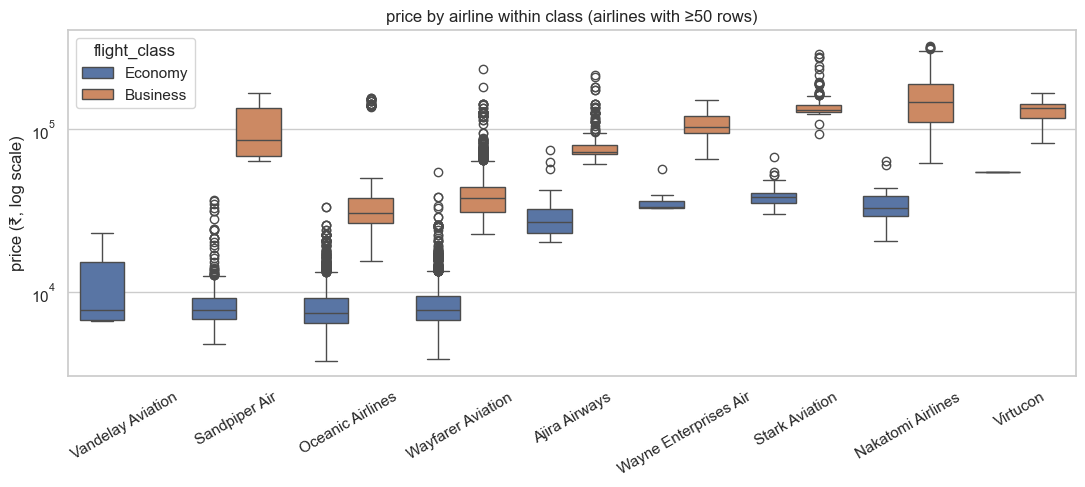

In [7]:
top = air.index[air["n"] >= 50]
sub = train[train["airline"].isin(top)]
order = sub.groupby("airline")[TARGET].median().sort_values().index

fig, ax = plt.subplots(figsize=(13, 4.5))
sns.boxplot(data=sub, x="airline", y=TARGET, hue="flight_class", hue_order=CLASSES, order=order, ax=ax)
ax.set(yscale="log", ylabel="price (₹, log scale)", xlabel="", title="price by airline within class (airlines with ≥50 rows)")
ax.tick_params(axis="x", rotation=30)
save("2_3_airline")

**What this cell does:** Computes R² for a very simple "model": predict each ticket's log(price) as the average of its group (its class, or its airline within a class). It also lists, per airline, what share of its Economy tickets cost more than ₹20k.

**Why:** R² turns "this feature looks important" into a number: the fraction of price variation explained by that one grouping. That lets us rank features before building any model. The ₹20k check tests a specific hypothesis from the box plot: the expensive Economy tickets come from particular airlines, not random noise.

In [8]:
# How much of the spread in log(price) does a single grouping explain? (R² of predicting each row by its group mean)
def r2_by_group(df, col):
    y = np.log(df[TARGET])
    return 1 - ((y - y.groupby(df[col]).transform("mean")) ** 2).sum() / ((y - y.mean()) ** 2).sum()

print(f"all rows   | flight_class alone: R² = {r2_by_group(train, 'flight_class'):.2f}")
known = train.dropna(subset=["airline"])
for cls in CLASSES:
    print(f"{cls:10s} | airline alone:      R² = {r2_by_group(known[known.flight_class == cls], 'airline'):.2f}")

# Economy tickets above ₹20k: which airlines sell them?
eco = train[train["flight_class"] == "Economy"]
print("\nshare of Economy tickets > ₹20k, by airline:")
print(eco.groupby("airline")[TARGET].apply(lambda s: (s > 20_000).mean()).round(2).sort_values().to_string())

all rows   | flight_class alone: R² = 0.78
Economy    | airline alone:      R² = 0.32
Business   | airline alone:      R² = 0.76

share of Economy tickets > ₹20k, by airline:
airline
Hooli Airways            0.00
Massive Dynamic          0.00
Oceanic Airlines         0.01
Wayfarer Aviation        0.01
Sandpiper Air            0.02
Vandelay Aviation        0.08
Ajira Airways            1.00
Black Mesa Air           1.00
Nakatomi Airlines        1.00
Omni Consumer Flights    1.00
Stark Aviation           1.00
Virtucon                 1.00
Wayne Enterprises Air    1.00


**Observations (2.3)**

- **Airline is the second big factor, and it interacts strongly with class.** Within Business, airline alone explains **R² = 0.76** of log(price). Within Economy it explains 0.32.
- Airlines split cleanly into two groups:
  - **Budget carriers** (Oceanic, Wayfarer, Sandpiper, Vandelay, …): Economy around ₹7–9k; ≤ 8% of their Economy tickets exceed ₹20k.
  - **Premium carriers** (Ajira, Stark, Nakatomi, Wayne Enterprises, Virtucon, Omni, Black Mesa): **100%** of their Economy tickets exceed ₹20k, so their Economy costs about as much as budget Business. Their Business fares run ₹70k–₹200k.
- Raw airline medians are misleading because of class mix. For example, Wayfarer looks pricier than Oceanic mostly because 48% of its tickets are Business vs 26%. Always compare within class.
- 9 airlines have fewer than 50 rows (some only 2). Their one-hot coefficients will be noisy, so consider grouping rare airlines.
- **Implication:** the large Economy tail (outliers above ₹20k in 2.2) isn't noise; it's premium-carrier Economy. Airline × class interaction terms matter for linear models. Trees will find this split on their own.

## 2.4 Stops and duration

**Why look:** more stops usually means longer flights, so these two features likely carry overlapping information. We check each against price (within class) and against each other.

**What this cell does:** Counts rows per (stops, class), prints median price per (stops, class), and plots price by stops (split by class) next to duration by stops.

**Why:** The counts show whether `stops` is tangled up with class (if Business is mostly one-stop, a raw stops-vs-price plot would really be showing a class effect). The duration plot checks whether stops and duration carry the same information. Two features that move together (collinearity) make linear-model coefficients unstable.

flight_class  Business  Economy
stops                          
zero              2821     8144
one               3495     1063
two_or_more         64        2

flight_class  Economy  Business
stops                          
zero             7555     33712
one              7697     61789
two_or_more     37996    125611


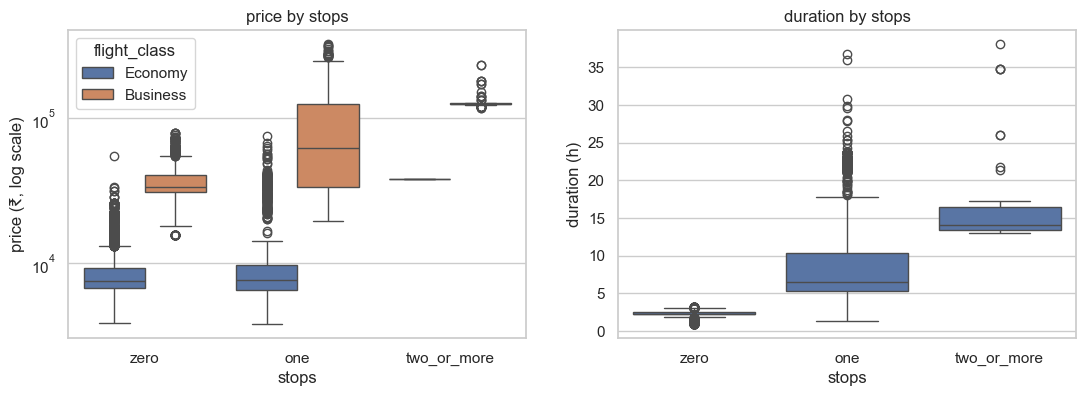

In [9]:
print(pd.crosstab(train["stops"], train["flight_class"]).reindex(STOPS).to_string())
print()
print(train.pivot_table(index="stops", columns="flight_class", values=TARGET, aggfunc="median")
      .reindex(STOPS)[CLASSES].round(0).to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=train, x="stops", y=TARGET, hue="flight_class", order=STOPS, hue_order=CLASSES, ax=axes[0])
axes[0].set(yscale="log", ylabel="price (₹, log scale)", title="price by stops")
sns.boxplot(data=train, x="stops", y="duration", order=STOPS, ax=axes[1])
axes[1].set(title="duration by stops", ylabel="duration (h)")
save("2_4a_stops")

**What this cell does:** Scatter-plots price vs duration separately for each class, then prints the Spearman correlation per class.

**Why:** We look within class for the same confounding reason as before. Spearman correlation measures whether price tends to rise when duration rises, without assuming a straight-line relationship. That's the right tool here because the scatter is clustered and not linear.

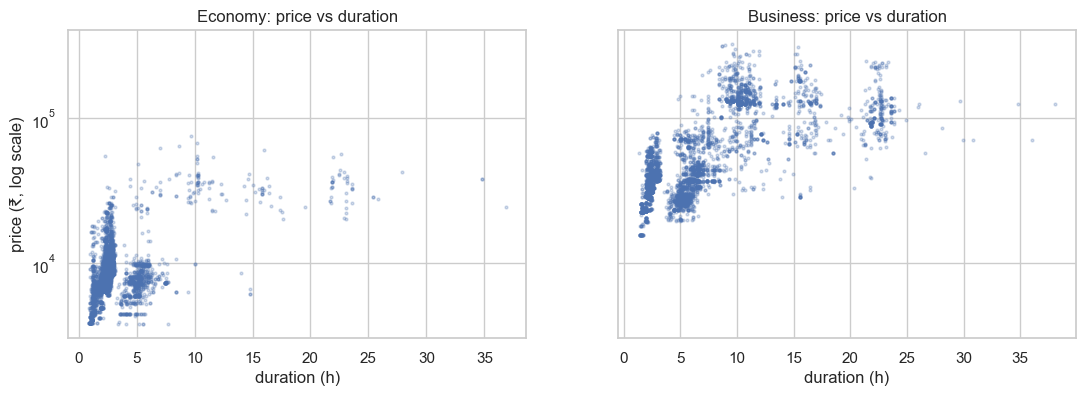

Economy   Spearman(duration, price) = 0.44
Business  Spearman(duration, price) = 0.68


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, cls in zip(axes, CLASSES):
    d = train[train["flight_class"] == cls]
    ax.scatter(d["duration"], d[TARGET], s=4, alpha=0.25)
    ax.set(title=f"{cls}: price vs duration", xlabel="duration (h)", yscale="log")
axes[0].set_ylabel("price (₹, log scale)")
save("2_4b_duration")

for cls in CLASSES:
    d = train[train["flight_class"] == cls].dropna(subset=["duration"])
    print(f"{cls:9s} Spearman(duration, price) = {d['duration'].corr(d[TARGET], method='spearman'):.2f}")

**Observations (2.4)**

- **Stops depend strongly on class:** 88% of Economy is non-stop, while most Business (55%) is one-stop. `two_or_more` has only 66 rows, almost all Business.
- Within each class, price rises with stops (Business: zero ₹33.7k → one ₹61.8k → two+ ₹125.6k). Duration rises with stops too, so **stops and duration overlap** in what they tell us (collinear for linear models).
- Price vs duration is positive but clustered rather than a clean line (Spearman 0.44 Economy, 0.68 Business). The clusters are mostly airline/route groups. Long flights (> 8 h) in Economy are almost all priced at ₹20k+ (premium carriers).
- **Implication:** encode `stops` as ordinal 0/1/2. A log or binned `duration` may fit better than a raw linear term. Expect Lasso to drop one of stops/duration.

## 2.5 Days left until departure

**Why look:** fares usually jump in the last days before departure. If the relationship is curved, a single linear coefficient on `days_left` can't capture it — that would justify polynomial terms or bins (plan model #3).

**What this cell does:** Plots the median price for each value of `days_left` (1–57) per class, prints median price in three buckets (≤ 3 days, 4–15, > 15), and counts how many rows each `days_left` value has.

**Why:** We expected fares to climb as departure approaches, which would need a non-linear term. The buckets give a robust summary that isn't thrown off by noisy single days. The row counts tell us how much to trust each point on the line (a median of 15 rows is unreliable).

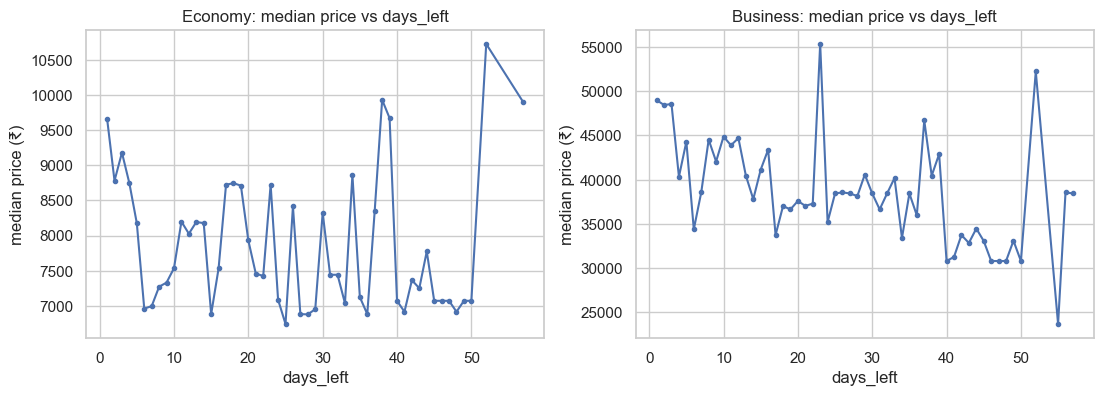

rows per days_left value: median 327 | min 15 at day 55
days_left values absent from train: [51, 53, 54]
tail (days > 49): {50: 124, 52: 107, 55: 15, 56: 26, 57: 97}
Economy   median price  days_left<=3:     9099 | 4-15:     7530 | >15:     7453
Business  median price  days_left<=3:    48562 | 4-15:    41506 | >15:    37771


In [11]:
dl = train.groupby(["flight_class", "days_left"])[TARGET].median().reset_index()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, cls in zip(axes, CLASSES):
    d = dl[dl["flight_class"] == cls]
    ax.plot(d["days_left"], d[TARGET], marker="o", ms=3)
    ax.set(title=f"{cls}: median price vs days_left", xlabel="days_left", ylabel="median price (₹)")
save("2_5_days_left")

counts = train["days_left"].value_counts().sort_index()
print("rows per days_left value: median", int(counts.median()), "| min", counts.min(), "at day", counts.idxmin())
print("days_left values absent from train:", sorted(set(range(1, 58)) - set(counts.index)))
print("tail (days > 49):", counts[counts.index > 49].to_dict())

for cls in CLASSES:
    d = train[train["flight_class"] == cls]
    print(f"{cls:9s} median price  days_left<=3: {d.loc[d.days_left <= 3, TARGET].median():>8.0f}"
          f" | 4-15: {d.loc[d.days_left.between(4, 15), TARGET].median():>8.0f}"
          f" | >15: {d.loc[d.days_left > 15, TARGET].median():>8.0f}")

**Observations (2.5)**

- **The effect of `days_left` is weaker and noisier than expected.** The only consistent pattern is a rise in the last ~4 days: Economy median ₹9,099 for ≤ 3 days vs ₹7,453 for > 15 days (+22%); Business ₹48.6k vs ₹37.8k (+29%).
- Beyond that, per-day medians jump around by ±20% with no smooth trend. Each point is a median of only ~100–200 rows per class, and the airline mix differs from day to day.
- The tail is sparse: days 51, 53 and 54 never appear, and day 55 has only 15 rows.
- **Implication:** don't expect a polynomial in `days_left` to help much. A simple "last few days" indicator or a coarse binning is the honest encoding. Test it in CV rather than assuming.

## 2.6 Time slots and routes

**Why look:** these are low-cardinality categoricals (6 slots, 6 cities each). One-hot encoding them is cheap; the question is whether they carry signal beyond class.

**What this cell does:** Box plots of Economy price for each departure and arrival time slot.

**Why:** Restricting to Economy keeps the class effect from masking anything. If the boxes look about the same across slots, these features carry little signal. That tells us not to spend effort engineering them.

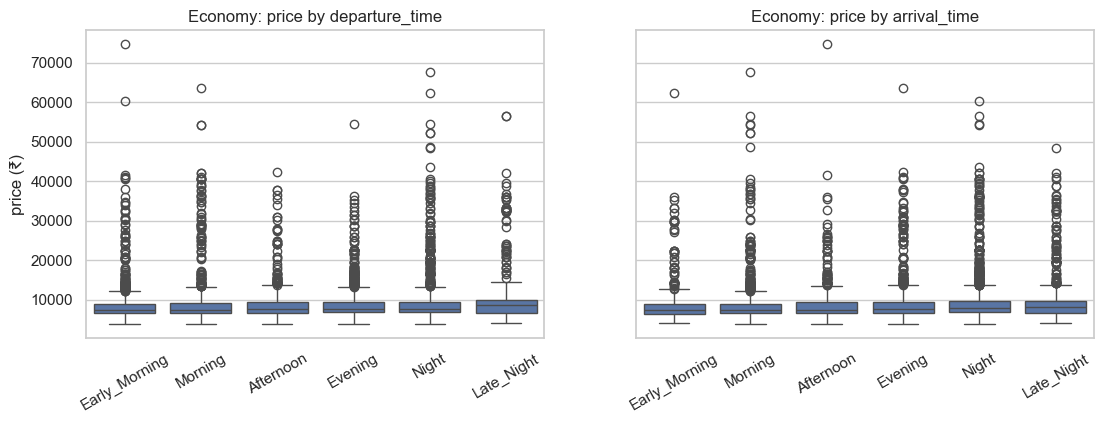

In [12]:
eco = train[train["flight_class"] == "Economy"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, col in zip(axes, ["departure_time", "arrival_time"]):
    sns.boxplot(data=eco, x=col, y=TARGET, order=SLOTS, ax=ax)
    ax.set(title=f"Economy: price by {col}", xlabel="", ylabel="price (₹)")
    ax.tick_params(axis="x", rotation=30)
save("2_6a_time_slots")

**What this cell does:** Builds a source × destination grid of median Economy price and shows it as a heatmap. It also checks that no flight has the same source and destination.

**Why:** This checks whether *where* you fly matters, and whether A→B costs the same as B→A. If routes are asymmetric, we need source and destination as separate features rather than an unordered "city pair".

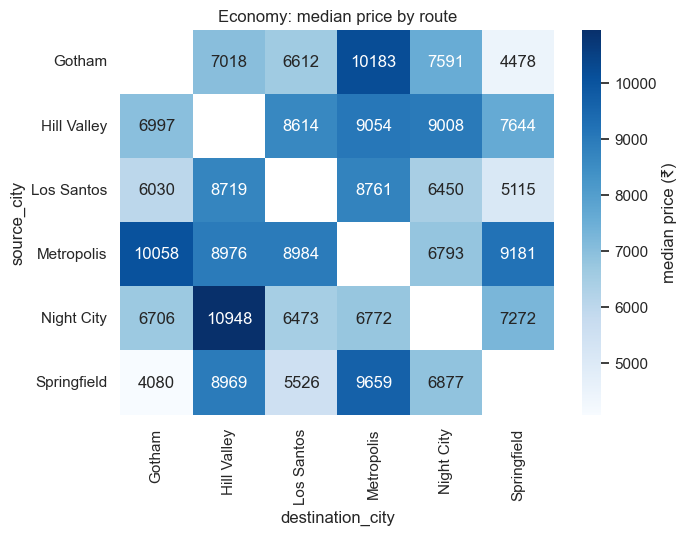

same source & destination rows: 0


In [13]:
eco_route = eco.pivot_table(index="source_city", columns="destination_city", values=TARGET, aggfunc="median")

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(eco_route, annot=True, fmt=".0f", cmap="Blues", ax=ax, cbar_kws={"label": "median price (₹)"})
ax.set(title="Economy: median price by route")
save("2_6b_routes")

print("same source & destination rows:", (train.source_city == train.destination_city).sum())

**Observations (2.6)**

- **Departure and arrival time slots barely move Economy prices.** The medians are nearly flat across all 6 slots; only `Late_Night` is slightly higher. Weak signal, but one-hot encoding them is cheap.
- **Routes matter moderately:** Economy route medians range from ₹4,080 (Springfield→Gotham) to ₹10,948 (Night City→Hill Valley). Routes are roughly but **not exactly symmetric** (Gotham→Springfield ₹4,478 vs Springfield→Gotham ₹4,080).
- All 30 directed routes are present, and no row has source = destination.
- **Implication:** one-hot `source_city` and `destination_city` separately (12 columns). A full route one-hot (30 columns) is an option for trees or interaction models, but test it in CV.

## 2.7 Data quality

**Why look:** missing values have to be handled before any sklearn model will train. The key question for each missing column: *can we recover the true value, or do we have to guess?*

**What this cell does:** Counts missing values per column in train and test, checks whether `airline` and `duration` tend to go missing together, and compares the median price of rows with vs without each missing value.

**Why:** How we handle missing data depends on **why** it's missing. If missingness is linked to price (e.g. expensive tickets more often lack duration), filling in a typical value would bias the model. If it's unrelated ("missing completely at random"), filling is safe. The "expected if independent" number is what we'd see by pure chance: missing-rate × missing-rate × rows.

In [14]:
miss = pd.DataFrame({"train_missing": train.isna().sum(), "test_missing": test.isna().sum()})
miss["train_%"] = (100 * miss["train_missing"] / len(train)).round(1)
miss = miss[(miss["train_missing"] > 0) | (miss["test_missing"] > 0)]
print(miss.to_string())

both = (train["airline"].isna() & train["duration"].isna()).sum()
print(f"\nrows missing both airline and duration: {both} "
      f"(≈{train['airline'].isna().mean() * train['duration'].isna().mean() * len(train):.0f} expected if independent)")

# Is missingness related to price? (If not, dropping/filling is less risky.)
for col in ["airline", "duration"]:
    m = train[col].isna()
    print(f"median price | {col} missing: {train.loc[m, TARGET].median():.0f} vs present: {train.loc[~m, TARGET].median():.0f}")

          train_missing  test_missing  train_%
airline            3089         799.0     19.8
duration           3095         776.0     19.9

rows missing both airline and duration: 602 (≈613 expected if independent)
median price | airline missing: 10213 vs present: 10183
median price | duration missing: 10269 vs present: 10183


### Can `airline` be recovered from the flight code?
The flight code looks like `"6E 285"` — the prefix before the space is the carrier code. If each prefix maps to exactly one airline in the rows where airline *is* known, we can fill the missing ones exactly.

**What this cell does:** Stacks train and test together, extracts the flight-code prefix (e.g. `6E` from `6E 285`), and checks that every prefix maps to exactly one airline and that every row with a missing airline has a known prefix.

**Why:** If prefix → airline is a strict one-to-one lookup, missing airlines can be filled **exactly**. That's not an estimate, so it adds no error. Test is included because its missing airlines need filling too, and this uses only flight codes, never prices, so it doesn't leak the target.

In [15]:
full = pd.concat([train.drop(columns=TARGET), test], ignore_index=True)
full["prefix"] = full["flight"].str.split().str[0]

per_prefix = full.dropna(subset=["airline"]).groupby("prefix")["airline"].nunique()
print("prefixes:", full["prefix"].nunique(), "| prefixes mapping to >1 airline:", (per_prefix > 1).sum())

per_airline = full.dropna(subset=["airline"]).groupby("airline")["prefix"].unique()
print(per_airline[per_airline.str.len() > 1].to_string())  # airlines that use more than one prefix

recoverable = full.loc[full["airline"].isna(), "prefix"].isin(per_prefix.index)
print(f"missing airline rows recoverable via prefix: {recoverable.sum()} / {len(recoverable)}")

prefixes: 20 | prefixes mapping to >1 airline: 0
airline
Wayfarer Aviation    [IX, AI]
missing airline rows recoverable via prefix: 3888 / 3888


### Can `duration` be recovered?
The same flight on the same route with the same stops should have (nearly) the same duration. Check: (1) how consistent duration is within such a group, (2) how many missing rows have a group with a known value.

**What this cell does:** Groups rows by (flight, source, destination, stops). It measures how much duration varies inside each group, then counts how many rows with a missing duration belong to a group where duration is known.

**Why:** The same scheduled flight on the same route should take the same time. If duration barely varies within these groups, a group's known duration is a near-exact fill for its missing rows. That's far better than filling every gap with one overall average.

In [16]:
key = ["flight", "source_city", "destination_city", "stops"]
known = full.dropna(subset=["duration"])
spread = known.groupby(key)["duration"].agg(["size", "std"]).query("size > 1")
print(f"groups with ≥2 known durations: {len(spread)} | share with std == 0: {(spread['std'] == 0).mean():.1%}"
      f" | median std: {spread['std'].median():.2f} h")

has_group = full.loc[full["duration"].isna()].merge(
    known[key].drop_duplicates(), on=key, how="left", indicator=True)["_merge"].eq("both")
print(f"missing duration rows with a known same-group value: {has_group.sum()} / {len(has_group)}")

groups with ≥2 known durations: 1386 | share with std == 0: 76.1% | median std: 0.00 h
missing duration rows with a known same-group value: 3784 / 3871


### Duplicates and the noise floor

**What this cell does:** Finds train rows whose features are identical to another row's, checks how many of those groups disagree on price, counts exact copies (same features *and* same price), and checks that test ids line up with the sample submission.

**Why:** Exact copies are a cross-validation trap: if one copy lands in the training folds and the other in the validation fold, the model is graded on a row it has already seen, so the score is too optimistic. Identical features with *different* prices show the noise floor, the error no model can remove. The id check makes sure our submission rows will line up with Kaggle's.

In [17]:
feats = [c for c in train.columns if c not in ("id", TARGET)]
dup_mask = train.duplicated(feats, keep=False)
g = train[dup_mask].groupby(feats, dropna=False)[TARGET]
spread = (g.max() - g.min())
print(f"rows sharing identical features with another row: {dup_mask.sum()} in {g.ngroups} groups")
print(f"groups whose prices differ: {(spread > 0).sum()} | median price gap within a group: {spread.median():.0f}")
exact = train.duplicated(feats + [TARGET], keep="first")
print(f"exact copies (features AND price identical, counting only the 2nd+ copy): {exact.sum()}"
      f" | spread over ids {train.loc[exact, 'id'].min()}–{train.loc[exact, 'id'].max()}")
print(f"ids: train {train.id.min()}–{train.id.max()}, test {test.id.min()}–{test.id.max()}"
      f" | sample_submission ids match test order: {(sample_sub.id.values == test.id.values).all()}")

rows sharing identical features with another row: 624 in 310 groups
groups whose prices differ: 35 | median price gap within a group: 0
exact copies (features AND price identical, counting only the 2nd+ copy): 279 | spread over ids 271–15585
ids: train 1–15589, test 1–3898 | sample_submission ids match test order: True


**Observations (2.7)**

- **`airline` (19.8%) and `duration` (19.9%) are missing**, with the same rates in test. They go missing **independently of each other** (602 rows missing both vs ≈613 expected if independent) and **independently of price** (median ₹10,213 / ₹10,269 when missing vs ₹10,183 when present). This looks like missing completely at random, so filling them shouldn't bias the model.
- **`airline` is 100% recoverable:** 20 flight-code prefixes, each mapping to exactly one airline (Wayfarer uses two: AI and IX). All 3,888 missing rows (train + test) have a known prefix. This is an exact lookup, not a guess.
- **`duration` is ~98% recoverable:** within the same (flight, source, destination, stops) group, 76% of groups have exactly one duration value (median std 0 h). 3,784 of 3,871 missing rows have such a group. The remaining 87 rows get the (route, stops) median.
- **Duplicates:** 624 rows share identical features with another row (310 groups). **279 are exact copies, including price**, scattered across ids rather than in a block like classification. Only 35 groups have conflicting prices, which is the true noise floor and is small.
- **Implication:** drop the 279 exact copies before CV. They're less severe than the 2,500 classification copies, but a copy in the validation fold still leaks. Train and test ids both start at 1, so `id` is just a row number; never use it as a feature.

## 2.8 Train vs test distribution

**Why look:** CV on train only predicts leaderboard performance if test looks like train. Big shifts would mean CV scores mislead us.

**What this cell does:** For each categorical column, computes the largest gap between a category's share in train vs test and counts test categories never seen in train. It also compares numeric means, counts test rows with unseen flight codes and new airline names, and overlays train/test density curves.

**Why:** Cross-validation estimates how the model will do on data **like train**. That estimate only carries over to the leaderboard if test looks like train. Unseen categories also matter in practice: an encoder that hasn't seen a value can crash at prediction time unless it's told to ignore unknowns.

          column  max_share_diff_pct  test_values_unseen_in_train
         airline                1.70                            1
     source_city                1.13                            0
destination_city                0.63                            0
  departure_time                1.00                            0
    arrival_time                2.12                            0
           stops                0.42                            0
    flight_class                0.88                            0
duration  train mean 4.30 / test mean 4.25
days_left train mean 22.46 / test mean 22.21
airline names in test but not train: ['Tyrell Aeronautics'] | rows: 1 | their flight prefixes: ['BG']

test rows with a flight code never seen in train: 35 (0.9%)


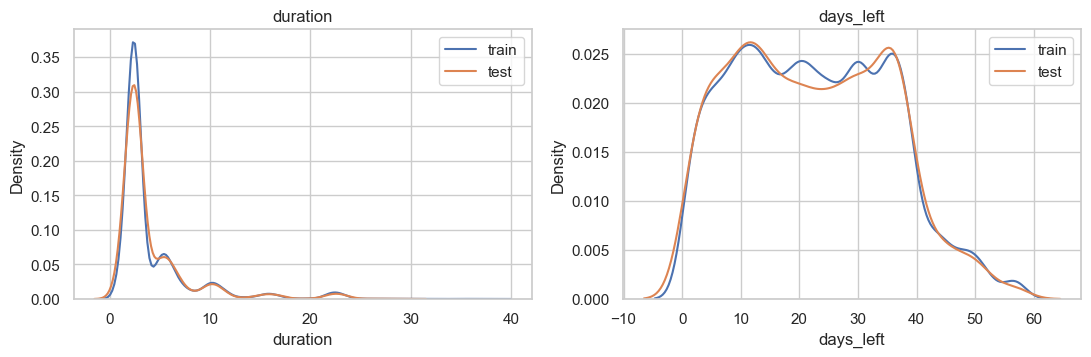

In [18]:
cats = ["airline", "source_city", "destination_city", "departure_time", "arrival_time", "stops", "flight_class"]
rows = []
for c in cats:
    p_tr = train[c].value_counts(normalize=True)
    p_te = test[c].value_counts(normalize=True)
    rows.append({"column": c, "max_share_diff_pct": round(100 * p_tr.subtract(p_te, fill_value=0).abs().max(), 2),
                 "test_values_unseen_in_train": len(set(test[c].dropna()) - set(train[c].dropna()))})
print(pd.DataFrame(rows).to_string(index=False))

for c in ["duration", "days_left"]:
    print(f"{c:9s} train mean {train[c].mean():.2f} / test mean {test[c].mean():.2f}")

new_air = sorted(set(test["airline"].dropna()) - set(train["airline"].dropna()))
print("airline names in test but not train:", new_air, "| rows:", test["airline"].isin(new_air).sum(),
      "| their flight prefixes:", test.loc[test["airline"].isin(new_air), "flight"].str.split().str[0].unique().tolist())
unseen = ~test["flight"].isin(train["flight"])
print(f"\ntest rows with a flight code never seen in train: {unseen.sum()} ({unseen.mean():.1%})")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
for ax, c in zip(axes, ["duration", "days_left"]):
    sns.kdeplot(train[c], label="train", ax=ax); sns.kdeplot(test[c], label="test", ax=ax)
    ax.set(title=c); ax.legend()
save("2_8_train_vs_test")

**Observations (2.8)**

- **Test closely matches train:** every categorical's shares differ by ≤ 2.1 percentage points. `duration` and `days_left` means are nearly identical and their densities overlap almost exactly.
- One airline name appears only in test (`Tyrell Aeronautics`, 1 row, prefix `BG`), and 35 test rows (0.9%) use flight codes never seen in train.
- **Implication:** CV on train should predict leaderboard performance well. Encoders must handle unseen categories (`handle_unknown="ignore"`). Don't one-hot the raw `flight` code (≈1,070 values); use the prefix/airline instead.

## Summary → what this means for preprocessing and models

**What drives price, in order:** cabin class (R² 0.78 alone) → airline *within* class (premium vs budget carriers) → stops/duration → route → days_left (only the last ~4 days) → time slots (barely).

**Preprocessing decisions this EDA justifies**
1. Fill `airline` from the flight-code prefix (exact lookup; can run before CV because nothing is learned).
2. Fill `duration` from the same (flight, route, stops) group median, falling back to the (route, stops) median. Fit these medians inside the CV pipeline.
3. Drop the 279 exact duplicate rows before splitting into folds.
4. `stops` → ordinal 0/1/2. One-hot: airline (group the rare ones), source, destination, time slots, class. Drop `id` and the raw `flight` code.
5. Model log(price) and transform predictions back. Confirm against the Kaggle metric.
6. Use `handle_unknown="ignore"` for unseen test categories.

**Modelling expectations**
- Linear models need **class × airline (and class × stops/duration) interactions**, or separate per-class models. A plain additive model can't express "premium Economy ≈ budget Business".
- Decision trees should pick up these interactions automatically, so expect them to beat plain OLS.
- `days_left` and time slots are weak, so don't spend tuning effort on them.

**Corrections to the earlier profiling in `plans/01-project-plan.md`:** duplicates are 279 exact copies + 35 conflicting groups (not "314 rows that may have different prices"). The expected strong non-linear `days_left` effect isn't really there.